# Myocardial infarction — fresh signal-strength estimation audit

This is a **new raw-data analysis**, not a replot of the archived fit. The original notebook,
gold-standard figure, and previous sensitivity results remain unchanged. The specification is
the paragraph “Estimating the signal strength matrix” in
`../WERM-paper/JRSSB-revision-rebuttal/JRSSB_v2.tex`, equations
`b-fp-implicit` through `cross-cov-fp-implicit` and `theta-deb-fp-eqn`.
The full mathematical derivation and legacy-code audit are in
`docs/myocardial_signal_strength_audit.md`.

**Prior:** one null configuration, all observations assigned to signal 0, has mass 1/2.
Conditional on one change, give equal mass to each valid split at the start of a distinct age.
Exclude empty-segment boundaries and missing ages. Derive the fitting weights exactly by
marginalizing this same prior. This differs deliberately from the preceding reference-preserving
analysis, which retained the two legacy boundary states as a mixture null.

**Fresh preprocessing:** UCI 579, target ZSN > 0, drop missing AGE, sort by AGE using the original
NumPy argsort convention, remove ID and AGE, mean-impute the other 110 features, center,
whiten with covariance ridge $10^{-6}$, and divide by $\sqrt n$. Use float64 throughout.
No intercept is added, matching the paper's present zero-mean logistic model. No coefficient,
adjusted-score, signal-strength, or fixed-point solution is loaded from the previous result.

In [1]:
import os
for name in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'): os.environ[name]='1'
from pathlib import Path
import hashlib, pickle, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.special import expit
from sklearn.linear_model import LinearRegression
import jax
jax.config.update('jax_enable_x64',True)
import jax.numpy as jnp
import WERM.estimators
from WERM.signal_strength import configuration_prior, empirical_adjustment, squared_logistic_state, estimate_signal_strength
from IPython.display import display

raw_path=Path('results/myocardial_raw_uci579.csv')
if not raw_path.exists():
    pd.read_csv('https://archive.ics.uci.edu/static/public/579/data.csv').to_csv(raw_path,index=False)
raw=pd.read_csv(raw_path)
data=raw.loc[raw.AGE.notna()].copy()
data=data.iloc[np.argsort(data.AGE.to_numpy())]
ages=data.AGE.to_numpy(float)
y=(data.ZSN.to_numpy()>0).astype(int)
features=list(raw.columns[2:112])
assert len(features)==110 and 'AGE' not in features and 'ZSN' not in features
X=data[features].to_numpy(float)
X=np.where(np.isnan(X),np.nanmean(X,axis=0),X)
X-=X.mean(axis=0)
n,p=X.shape;delta=n/p
values,vectors=eigh(X.T@X/n+1e-6*np.eye(p))
X=X@((vectors/np.sqrt(values))@vectors.T)/np.sqrt(n)
assert (n,p)==(1692,110) and np.isfinite(X).all()
unique_ages,indices=np.unique(ages,return_index=True)
locations=indices[indices>0]
eta,prior,phi=configuration_prior(n,locations)
assert len(locations)==61
np.testing.assert_allclose(prior[0],.5)
np.testing.assert_allclose(prior[1:].sum(),.5)
np.testing.assert_allclose(phi.sum(axis=0),1)
provenance=dict(raw_sha256=hashlib.sha256(raw_path.read_bytes()).hexdigest(),
                solver_sha256=hashlib.sha256(Path('WERM/signal_strength.py').read_bytes()).hexdigest(),
                paper_sha256=hashlib.sha256(Path('../WERM-paper/JRSSB-revision-rebuttal/JRSSB_v2.tex').read_bytes()).hexdigest(),
                n=n,p=p,prior='half null, half uniform over 61 age splits',float_dtype='float64')
fingerprint=hashlib.sha256(json.dumps(provenance,sort_keys=True).encode()).hexdigest()[:16]
output=Path('results')/('myocardial_fresh_rho_audit_'+fingerprint)
output.mkdir(exist_ok=True)
print('n,p,delta:',n,p,delta,'; positive response proportion:',y.mean())
print('Output:',output)

/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


n,p,delta: 1692 110 15.381818181818181 ; positive response proportion: 0.23167848699763594
Output: results/myocardial_fresh_rho_audit_a59f94919f1919da


## Fresh auxiliary squared-loss WERM fit and empirical adjustment

Fit each weighted least-squares problem using the package's exact solver and the explicitly
supplied marginals. Check against independent sklearn weighted least squares. Estimate the
signal configuration by minimizing the fitted squared prediction error over the **same**
candidate grid (including the null). For squared loss the empirical $b$ equation is scalar,
strictly monotone, and solved with a bracketed root finder to $10^{-13}$ rather than a fixed
number of averaged Anderson updates. Record $S=(\Theta^{adj})^\top\Theta^{adj}/n$ without centering:
the paper specifies a second moment, not a centered covariance.

In [2]:
M_square=lambda u,v:jnp.square(u-v)
_,_,B=WERM.estimators.weighted_erm(
    X,y,M_square,2,1,0.,L_is_upper_bound=False,return_gof=True,return_B_hat=True,
    marginal_weights=phi,coefficient_loss='least_squares')
B=np.asarray(B)
independent=np.column_stack([LinearRegression(fit_intercept=False).fit(X,y,sample_weight=w).coef_ for w in phi])
np.testing.assert_allclose(X@B,X@independent,rtol=1e-8,atol=1e-9)
theta=X@B
scores=np.array([np.sum((theta[:,0]-y)**2) if e==-1 else
    np.sum((theta[:e,0]-y[:e])**2)+np.sum((theta[e:,1]-y[e:])**2) for e in eta])
eta_hat=int(eta[np.argmin(scores)])
psi=np.zeros(n,dtype=int) if eta_hat==-1 else (np.arange(n)>=eta_hat).astype(int)
adjusted,b=empirical_adjustment(theta,y,phi,delta,loss='squared')
S=adjusted.T@adjusted/n
b_residual=np.mean(1/(1+2*b[:,None]*phi),axis=1)-(1-1/delta)
assert np.max(abs(b_residual))<1e-12
print('Independent sklearn fit check passed.')
print('Pilot split index:',eta_hat,'; age:',ages[eta_hat] if eta_hat>=0 else '0 chgpts')
print('Empirical b:',b,'; root residual:',b_residual)
print('Empirical adjusted second moment:\n',S)

Independent sklearn fit check passed.
Pilot split index: 1127 ; age: 67.0
Empirical b: [0.04763084 0.13008004] ; root residual: [-1.11022302e-16  0.00000000e+00]
Empirical adjusted second moment:
 [[0.02653459 0.02760159]
 [0.02760159 0.03349759]]


## Joint signal-strength estimation: deterministic reduced equations

Let $a_{il}=2b_l\phi_{li}/(1+2b_l\phi_{li})$ and
$h_s=E[\sigma'(N(0,\rho_{ss}))]$. Integrating the Bernoulli observation noise and using
Gaussian integration by parts gives
$\Lambda_{sl}=h_s\overline{a_l1_{\psi=s}}/\overline{a_l}$.
With $A=\Lambda^\top\rho\Lambda$ and
$v_{il}=h_{\psi_i}(\rho\Lambda)_{\psi_i,l}$,
$K_{lm}=\delta\overline{a_la_m(A_{lm}-v_l-v_m+1/2)}/(1-\delta\overline{a_la_m})$.
These eliminate the nuisance fixed-point unknowns. Match $S=A+K$ by jointly fitting all
three entries of $\rho$ under a positive-definite constraint. No independently estimated
diagonals are imposed. Ten starting points check dependence on initialization.

An independent affine system identifies $C=\operatorname{diag}(h)\rho\operatorname{diag}(h)$.
When its operator has full rank, negative eigenvalues of the unique $C$ certify that no
positive-semidefinite $\rho$ solves these empirical equations, independently of optimization.
See the audit document for the full reduction and scalar inverse in the feasible case.

An optimizer stopping successfully is **not** equivalent to solving the paper's equations.
Report the actual Frobenius residual, conditioning, boundary proximity, and local Jacobian rank.
Check 80-node quadrature against 160 nodes before accepting numerical accuracy.

In [3]:
fit=estimate_signal_strength(S,phi,psi,delta)
rho_new=fit['rho']
state=fit['state']
certificate=fit['certificate']
print('Effective covariance required by exact moment matching:\n',certificate['effective_covariance'])
print('Its eigenvalues:',certificate['effective_eigenvalues'])
print('Linear operator rank/condition:',certificate['operator_rank'],certificate['operator_condition'])
print('Linear reconstruction error:',certificate['linear_residual'])
print('Infeasibility certified:',certificate['infeasibility_certified'])
state160=squared_logistic_state(rho_new,phi,psi,delta,quadrature_order=160)
quadrature_error=float(np.linalg.norm(state160['moment']-state['moment']))
np.testing.assert_allclose(state160['moment'],state['moment'],rtol=1e-8,atol=1e-10)
diagnostics=pd.DataFrame([dict(
    accepted=fit['accepted'],optimizer_success=fit['optimizer_success'],
    moment_Frobenius_residual=fit['residual_norm'],
    relative_moment_residual=fit['residual_norm']/np.linalg.norm(S),
    min_rho_eigenvalue=np.linalg.eigvalsh(rho_new).min(),
    correlation=rho_new[0,1]/np.sqrt(rho_new[0,0]*rho_new[1,1]),
    boundary=fit['boundary'],jacobian_rank=fit['jacobian_rank'],quadrature_error=quadrature_error)])
print('New constrained moment-fit candidate (not automatically accepted):\n',rho_new)
display(diagnostics)
display(pd.DataFrame([dict(start=i,success=r['success'],residual=r['residual']) for i,r in enumerate(fit['starts'])]))
print('Model-predicted second moment:\n',state['moment'])
print('Empirical minus predicted moment:\n',S-state['moment'])
print('Jacobian singular values:',fit['jacobian_singular_values'])
with (output/'fresh_rho_fit.pkl').open('wb') as handle:
    pickle.dump(dict(provenance=provenance,X=X,y=y,ages=ages,eta=eta,prior=prior,phi=phi,
                     B=B,theta=theta,adjusted=adjusted,S=S,eta_hat=eta_hat,b=b,fit=fit),handle)
diagnostics.to_csv(output/'diagnostics.csv',index=False)

Effective covariance required by exact moment matching:
 [[-0.03126414  0.0219892 ]
 [ 0.0219892  -0.03446053]]
Its eigenvalues: [-0.05490954 -0.01081513]
Linear operator rank/condition: 3 52.18020975835133
Linear reconstruction error: 1.3437110265466432e-17
Infeasibility certified: True
New constrained moment-fit candidate (not automatically accepted):
 [[ 0.16612066 -0.32803257]
 [-0.32803257  0.64775428]]


,accepted,optimizer_success,moment_Frobenius_residual,relative_moment_residual,min_rho_eigenvalue,correlation,boundary,jacobian_rank,quadrature_error
0,False,False,0.012997,0.224557,2.645384e-13,-1.0,True,3,0.0


,start,success,residual
0,0,False,0.012997
1,1,True,0.013026
2,2,True,0.013026
3,3,True,0.013026
4,4,True,0.013026
5,5,True,0.013026
6,6,True,0.013026
7,7,True,0.013026
8,8,False,0.012997
9,9,True,0.013026


Model-predicted second moment:
 [[0.0355587  0.03286626]
 [0.03286626 0.03915894]]
Empirical minus predicted moment:
 [[-0.00902411 -0.00526468]
 [-0.00526468 -0.00566135]]
Jacobian singular values: [0.01502869 0.00393284 0.00100882]


## Robustness to the fitting-weight and pilot-grid convention

As a diagnostic only, refit with the corrected age prior, a uniform observation-index prior,
and the legacy exactly-one-change weights. For this check allow all proper observation-index
pilot splits. Each setup recomputes its own fitted coefficients and adjusted moment. This
does not change the primary analysis; it checks whether the infeasibility is caused by the
new age-grid/prior choice.

In [4]:
robustness=[]
t=np.arange(n)/(n-1)
variants=[('Age-grid half-count',phi),('All-index half-count',np.array([1-.5*t,.5*t])),
          ('Legacy exactly-one',np.array([1-np.arange(1,n+1)/n,np.arange(1,n+1)/n]))]
from WERM.signal_strength import signal_strength_certificate
for label,weights in variants:
    beta=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in weights])
    pred=X@beta;cost=(pred-y[:,None])**2
    split=int(np.argmin(np.cumsum(cost[:,0])[:-1]+np.cumsum(cost[::-1,1])[::-1][1:])+1)
    adjusted_variant,_=empirical_adjustment(pred,y,weights,delta)
    cert=signal_strength_certificate(adjusted_variant.T@adjusted_variant/n,weights,
                                      (np.arange(n)>=split).astype(int),delta)
    robustness.append(dict(weights=label,pilot_split=split,rank=cert['operator_rank'],
        min_eigenvalue=cert['effective_eigenvalues'][0],max_eigenvalue=cert['effective_eigenvalues'][1],
        infeasibility_certified=cert['infeasibility_certified']))
display(pd.DataFrame(robustness))
pd.DataFrame(robustness).to_csv(output/'weighting_robustness.csv',index=False)

,weights,pilot_split,rank,min_eigenvalue,max_eigenvalue,infeasibility_certified
0,Age-grid half-count,1166,3,-0.058710,-0.010727,True
1,All-index half-count,1166,3,-0.037362,-0.009356,True
2,Legacy exactly-one,1081,3,-0.032106,-0.008921,True


## Fresh logistic-loss fit for the posterior stage

This stage uses **logistic loss**, not the auxiliary squared loss. First check whether
a finite unpenalized MLE exists: seek a direction $d$ with all signed margins nonnegative
and their sum at least one, on positive-weight rows. Such a direction strictly decreases
the logistic loss as its coefficient diverges, excluding a finite minimizer. Report both
the LP witness and sklearn's finite-iteration output; small gradients alone do not establish
existence. Do not silently add a penalty or claim an unconverged iterate is a finite MLE.

In [5]:
from sklearn.linear_model import LogisticRegression
from WERM.signal_strength import logistic_separation
M_logistic=lambda u,v:jnp.logaddexp(0.,u)-v*u
separation=[logistic_separation(X,y,w) for w in phi]
sklearn_logistic=np.column_stack([LogisticRegression(penalty=None,fit_intercept=False,
    solver='lbfgs',tol=1e-12,max_iter=10000).fit(X,y,sample_weight=w).coef_.ravel() for w in phi])
logistic_rows=[]
for l,(w,check) in enumerate(zip(phi,separation)):
    beta=sklearn_logistic[:,l]
    grad=X.T@(w*(expit(X@beta)-y))/w.sum()
    logistic_rows.append(dict(signal=l,separation=check['separated'],
        min_signed_margin=check.get('min_margin',np.nan),sum_signed_margins=check.get('sum_margins',np.nan),
        sklearn_finite_iterate_norm=np.linalg.norm(beta),sklearn_gradient_max=np.max(abs(grad))))
display(pd.DataFrame(logistic_rows))
logistic_mle_available=not any(check['separated'] for check in separation)
if logistic_mle_available:
    _,_,B_logistic=WERM.estimators.weighted_erm(X,y,M_logistic,2,1,0.,
        L_is_upper_bound=False,return_gof=True,return_B_hat=True,marginal_weights=phi,
        coefficient_loss='logistic',coefficient_solver_options={'tol':1e-8,'max_iter':30000})
    theta_logistic=X@B_logistic
    np.testing.assert_allclose(theta_logistic,X@sklearn_logistic,rtol=1e-4,atol=2e-4)
    adjusted_logistic,b_logistic=empirical_adjustment(theta_logistic,y,phi,delta,loss='logistic')
else:
    print('LOGISTIC MLE BLOCKED: validated recession directions found. Sklearn outputs above are finite iterates, not finite MLEs.')
with (output/'fresh_logistic_diagnostics.pkl').open('wb') as handle:
    pickle.dump(dict(separation=separation,sklearn_finite_iterates=sklearn_logistic,
                     finite_mle_available=logistic_mle_available,provenance=provenance),handle)

,signal,separation,min_signed_margin,sum_signed_margins,sklearn_finite_iterate_norm,sklearn_gradient_max
0,0,True,-4.096907e-14,1.0,2290.195272,6.402949e-10
1,1,True,-1.754014e-14,1.0,4616.412891,1.458083e-10


LOGISTIC MLE BLOCKED: validated recession directions found. Sklearn outputs above are finite iterates, not finite MLEs.


## Model adequacy and the posterior safety gate

Under the paper's present observation model, $Z_s$ is centered Gaussian and
$Y|Z_s\sim\mathrm{Bernoulli}(\sigma(Z_s))$. Symmetry implies $E[Y]=1/2$ for **every**
$\rho$, irrespective of the change-point prior. Compare this implication with observed prevalence.
This does not prove that a particular empirical moment system has no solution, but is an important
model-adequacy diagnostic. Adding an intercept would change the observation model and the
fixed-point expectations, and requires a deliberate scientific choice rather than silent tuning.

If the joint moment solve fails the residual/identification checks, no posterior is presented as
validated. The new fit is saved for inspection, but downstream logistic fitting, posterior, and
eigenvalue sensitivity require resolving that issue first. Nothing falls back to the old $\rho$.

Observed P(Y=1): 0.231678; centered zero-intercept logistic model implication: 0.500000


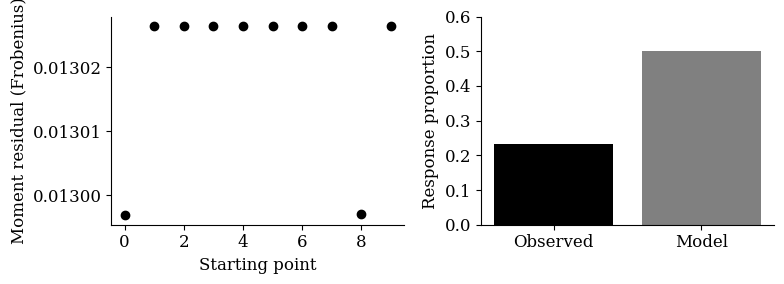

POSTERIOR BLOCKED: signal-strength feasibility and/or finite logistic MLE checks failed. No old-rho fallback or misleading new posterior has been generated.


In [6]:
print(f'Observed P(Y=1): {y.mean():.6f}; centered zero-intercept logistic model implication: 0.500000')
plt.rcParams.update({'font.family':'serif','font.size':12,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(8,3))
axes[0].plot(range(len(fit['starts'])),[r['residual'] for r in fit['starts']],'ko')
axes[0].set(xlabel='Starting point',ylabel='Moment residual (Frobenius)')
axes[1].bar(['Observed','Model'],[y.mean(),.5],color=['black','gray'])
axes[1].set(ylabel='Response proportion',ylim=(0,.6))
fig.tight_layout();plt.show()
if not fit['accepted'] or not logistic_mle_available:
    print('POSTERIOR BLOCKED: signal-strength feasibility and/or finite logistic MLE checks failed. No old-rho fallback or misleading new posterior has been generated.')
else:
    print('Moment gate passed; a freshly fitted logistic posterior still requires audited fixed-point and likelihood evaluation, not the legacy parameter-mismatched routine.')